# ResNet50 U-Net trained with FloodNet

Same RGB model as `unet_pretrained.ipynb` (phase 1 + augmentation), but FloodNet is added to the training data.
The question this notebook answers: **does extra FloodNet data help the model on Houston?**

- **Training data:** the Houston training tiles plus FloodNet mosaics from `fn.get_floodnet_mosaics`. Each epoch gets a
  new mosaic arrangement (`seed=epoch`), so the model never sees the same FloodNet layout twice.
- **RGB only:** FloodNet has no elevation, so this can't use the DEM model from `unet_dem.ipynb`.
- **Checkpoint and cutoff** are picked on the Houston val image (12), the same as the baseline, so the comparison is fair.
- **Scored on:** the Houston test images only (4, 5, 6, 7, 10, 11), the same split as `unet_pretrained.ipynb` and
  `unet_dem.ipynb`. FloodNet is used for training only.

Weights are saved to `../outputs/unet_floodnet.weights.h5`. The baseline weights (`unet_phase1_aug.weights.h5`) are
loaded at the end, if they exist, to compare both models on the same data.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

sys.path.append("../scripts")
from dataset import get_tiles, SPLITS
import floodnet as fn

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1793692277.572707    3511 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
MAX_UNKNOWN = 1.0     # same as the baseline: keep every Houston training tile
EPOCHS = 15           # same as the baseline
BATCH = 4
FLOODNET_WEIGHT = 1.0 # 1.0 = FloodNet tiles are drawn in proportion to their count. 3.0 = each FloodNet tile is seen ~3x as often

WEIGHTS_PATH = "../outputs/unet_floodnet.weights.h5"
BASELINE_PATH = "../outputs/unet_phase1_aug.weights.h5"   # from unet_pretrained.ipynb
BASELINE_CUTOFF = 0.7                                      # the cutoff picked in unet_pretrained.ipynb

## 1. Load and prepare the data

Houston: same tiles as the baseline, RGB only, with the same ResNet50 preprocessing. Scenes are loaded **one at a
time** and preprocessed right away, so the full 4-channel array (~2 GB) and extra copies are never in memory at the
same time (this matters on a machine with ~7 GB of RAM). The FloodNet training mosaics are built later, once per epoch.

In [3]:
from tensorflow.keras.applications.resnet50 import preprocess_input

def preprocess(x_rgb):
    return preprocess_input(x_rgb * 255.0)   # 0-1 to 0-255, then ResNet50's ImageNet preprocessing

def prepare_labels(y):
    return y.astype("float32")[..., None]    # (N, 256, 256) -> (N, 256, 256, 1)

def load_houston(images, **kwargs):
    """Same tiles as get_tiles, but one scene at a time, RGB only, already preprocessed."""
    X, y = [], []
    for i in images:
        Xi, yi = get_tiles([i], **kwargs)
        X.append(preprocess(Xi[..., :3]))
        y.append(yi)
        del Xi
    return np.concatenate(X), np.concatenate(y)

X_train_in, y_train = load_houston(SPLITS["train"], stride=128, max_unknown=MAX_UNKNOWN)
X_val_in, y_val = load_houston(SPLITS["val"])

X_test, y_test = get_tiles(SPLITS["test"])
X_test_rgb = X_test[..., :3].copy()          # kept for the plots in section 8
del X_test
X_test_in = preprocess(X_test_rgb)

_, y_fn_sample = fn.get_floodnet_mosaics(["train"], seed=0)   # one arrangement, just to report its size

for name, y in [("Houston train", y_train), ("Houston val", y_val), ("Houston test", y_test),
                ("FloodNet mosaics/epoch", y_fn_sample)]:
    known = y[y != -1]
    print(f"{name:23} {len(y):5} tiles  labeled {(y != -1).mean():5.1%}  flood (of labeled) {known.mean():.1%}")
print(f"Houston training inputs: {X_train_in.nbytes / 1e9:.2f} GB")

Houston train            1972 tiles  labeled 76.3%  flood (of labeled) 55.7%
Houston val               110 tiles  labeled 80.0%  flood (of labeled) 51.3%
Houston test              287 tiles  labeled 51.5%  flood (of labeled) 76.0%
FloodNet mosaics/epoch     47 tiles  labeled 72.5%  flood (of labeled) 15.8%
Houston training inputs: 1.55 GB


## 2. Labels

Labels stay as small int8 arrays (-1 / 0 / 1). They're turned into the float32 `(256, 256, 1)` shape the loss
expects only when needed: per batch while training, and here for the val image.

In [4]:
y_val_in = prepare_labels(y_val)
print(y_val_in.shape, "values:", np.unique(y_val_in))

(110, 256, 256, 1) values: [-1.  0.  1.]


## 3. Loss and model (same as the baseline)

In [5]:
def masked_bce(y_true, y_pred):
    known = tf.cast(y_true != -1, "float32")        # 1 = labeled pixel, 0 = unknown
    y_true = tf.where(y_true == -1, 0.0, y_true)    # BCE only understands 0/1
    loss = keras.losses.binary_crossentropy(y_true, y_pred)[..., None]
    return tf.reduce_sum(loss * known) / tf.reduce_sum(known)   # average over labeled pixels only

In [6]:
from tensorflow.keras.layers import Conv2D, BatchNormalization, Activation, Conv2DTranspose, Concatenate, Input
from tensorflow.keras.models import Model
from tensorflow.keras.applications import ResNet50

def conv_block(x, num_filters):
    x = Conv2D(num_filters, 3, padding="same")(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(num_filters, 3, padding="same")(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    return x

def decoder_block(x, skip_features, num_filters):
    x = Conv2DTranspose(num_filters, 2, strides=2, padding="same")(x)
    x = Concatenate()([x, skip_features])
    return conv_block(x, num_filters)

def build_resnet50_unet(input_shape):
    inputs = Input(input_shape)
    resnet50 = ResNet50(include_top=False, weights="imagenet", input_tensor=inputs)

    s1 = inputs                                          # 256
    s2 = resnet50.get_layer("conv1_relu").output         # 128
    s3 = resnet50.get_layer("conv2_block3_out").output   # 64
    s4 = resnet50.get_layer("conv3_block4_out").output   # 32
    b1 = resnet50.get_layer("conv4_block6_out").output   # 16

    d1 = decoder_block(b1, s4, 512)   # 32
    d2 = decoder_block(d1, s3, 256)   # 64
    d3 = decoder_block(d2, s2, 128)   # 128
    d4 = decoder_block(d3, s1, 64)    # 256

    outputs = Conv2D(1, 1, padding="same", activation="sigmoid")(d4)
    return Model(inputs, outputs, name="ResNet50_U-Net"), resnet50

model, encoder = build_resnet50_unet((256, 256, 3))
encoder.trainable = False   # phase 1: frozen encoder, like the baseline

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=masked_bce,
    jit_compile=False,   # XLA's compiled step needs more than an 8 GB GPU
)
print(model.input_shape, "->", model.output_shape)

I0000 00:00:1793692293.371040    3511 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5562 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070, pci bus id: 0000:2b:00.0, compute capability: 8.6


(None, 256, 256, 3) -> (None, 256, 256, 1)


## 4. Train on Houston + FloodNet mosaics

Each epoch:
1. Build a new FloodNet mosaic arrangement with `seed=epoch` (new neighbors, rotations and cut-off edges).
2. Mix it with the Houston tiles using `sample_from_datasets`, which draws randomly from both. The Houston tiles are
   fed by a generator straight from the numpy array in a new random order each epoch, so TensorFlow doesn't make its
   own 1.5 GB copy.
3. Train one epoch with the same flip/rotate augmentation as the baseline.
4. Save the weights if Houston val loss is the best so far.

In [7]:
def augment(x, y):
    k = tf.random.uniform([], 0, 4, dtype=tf.int32)
    x, y = tf.image.rot90(x, k), tf.image.rot90(y, k)
    flip = tf.random.uniform([]) < 0.5
    x = tf.cond(flip, lambda: tf.image.flip_left_right(x), lambda: x)
    y = tf.cond(flip, lambda: tf.image.flip_left_right(y), lambda: y)
    return x, y


def houston_tiles():
    # a new random order on every pass; labels become float32 one tile at a time
    for i in np.random.permutation(len(X_train_in)):
        yield X_train_in[i], y_train[i, ..., None].astype("float32")

TILE_SPEC = (tf.TensorSpec((256, 256, 3), tf.float32), tf.TensorSpec((256, 256, 1), tf.float32))
houston_ds = tf.data.Dataset.from_generator(houston_tiles, output_signature=TILE_SPEC)

with tf.device("/CPU:0"):   # keep data on the CPU; only each batch gets copied to the GPU
    val_ds = tf.data.Dataset.from_tensor_slices((X_val_in, y_val_in)).batch(BATCH)

def make_train_ds(epoch):
    X_fn, y_fn = fn.get_floodnet_mosaics(["train"], seed=epoch)
    with tf.device("/CPU:0"):
        fn_ds = tf.data.Dataset.from_tensor_slices((preprocess(X_fn), prepare_labels(y_fn)))
        n_h, n_f = len(X_train_in), len(X_fn) * FLOODNET_WEIGHT
        mixed = tf.data.Dataset.sample_from_datasets(
            [houston_ds.repeat(), fn_ds.shuffle(len(X_fn)).repeat()],
            weights=[n_h / (n_h + n_f), n_f / (n_h + n_f)],
            seed=epoch,
        )
        steps = int(np.ceil((len(X_train_in) + len(X_fn)) / BATCH))   # one pass over Houston + this epoch's mosaics
        ds = mixed.map(augment, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(2)
    return ds, steps

epoch  1/15  loss 0.3036  val_loss 0.6988  (saved)
epoch  2/15  loss 0.2502  val_loss 0.7885
epoch  3/15  loss 0.2446  val_loss 0.6466  (saved)
epoch  4/15  loss 0.1962  val_loss 0.6435  (saved)
epoch  5/15  loss 0.1814  val_loss 0.6856
epoch  6/15  loss 0.1768  val_loss 0.6924
epoch  7/15  loss 0.1493  val_loss 0.5742  (saved)
epoch  8/15  loss 0.1418  val_loss 0.7541
epoch  9/15  loss 0.1384  val_loss 0.5556  (saved)
epoch 10/15  loss 0.1493  val_loss 0.6020
epoch 11/15  loss 0.1177  val_loss 0.8750
epoch 12/15  loss 0.1216  val_loss 0.9824
epoch 13/15  loss 0.1002  val_loss 0.9553
epoch 14/15  loss 0.0961  val_loss 0.9224
epoch 15/15  loss 0.1000  val_loss 0.8432


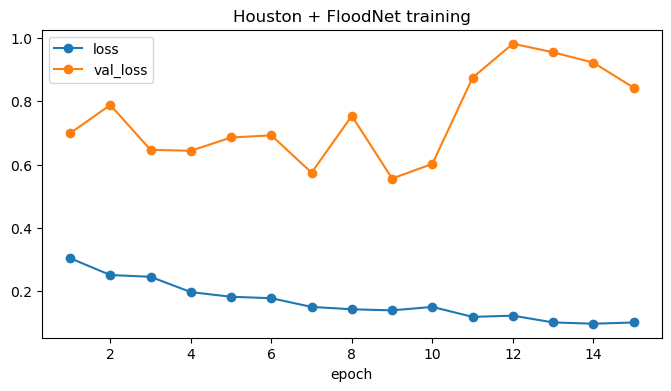

In [14]:
Path("../outputs").mkdir(exist_ok=True)

log = []
best_val = np.inf
for epoch in range(EPOCHS):
    train_ds, steps = make_train_ds(epoch)
    h = model.fit(train_ds, validation_data=val_ds, epochs=1, steps_per_epoch=steps, verbose=0)
    loss, val_loss = h.history["loss"][0], h.history["val_loss"][0]

    saved = val_loss < best_val
    if saved:
        best_val = val_loss
        model.save_weights(WEIGHTS_PATH)
    log.append({"epoch": epoch + 1, "loss": loss, "val_loss": val_loss})
    print(f"epoch {epoch + 1:2}/{EPOCHS}  loss {loss:.4f}  val_loss {val_loss:.4f}" + ("  (saved)" if saved else ""))

log = pd.DataFrame(log)
ax = log.plot(x="epoch", y=["loss", "val_loss"], marker="o", figsize=(8, 4))
ax.set_title("Houston + FloodNet training")
plt.show()

## 5. Pick the cutoff on Houston val

Same idea as the baseline: try several probability cutoffs on the val image and keep the one with the best
average of flood IoU and dry IoU.

In [15]:
def predict_probs(m, X, chunk=64):
    # predicts in chunks, so Keras never copies the whole input array at once
    return np.concatenate([m.predict(X[i:i + chunk], batch_size=8, verbose=0)[..., 0] for i in range(0, len(X), chunk)])

def iou_scores(probs, y, cutoff):
    # flood IoU, dry IoU and predicted flood share, over labeled pixels only
    known = y != -1
    pred_flood = probs > cutoff
    true_flood, true_dry = y == 1, y == 0
    flood = np.sum(pred_flood & true_flood & known) / np.sum((pred_flood | true_flood) & known)
    dry = np.sum(~pred_flood & true_dry & known) / np.sum((~pred_flood | true_dry) & known)
    return flood, dry, pred_flood[known].mean()

model.load_weights(WEIGHTS_PATH)
val_probs = predict_probs(model, X_val_in)

rows = []
for cut in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    f, d, says = iou_scores(val_probs, y_val, cut)
    rows.append({"cutoff": cut, "flood IoU": f, "dry IoU": d, "mean IoU": (f + d) / 2, "says flood": says})
cutoffs = pd.DataFrame(rows)

CUTOFF = cutoffs.loc[cutoffs["mean IoU"].idxmax(), "cutoff"]
print(f"best cutoff on val: {CUTOFF}   (label says flood: {(y_val[y_val != -1] == 1).mean():.1%})")
cutoffs.round(3)

best cutoff on val: 0.7   (label says flood: 51.3%)


,cutoff,flood IoU,dry IoU,mean IoU,says flood
0,0.3,0.640,0.474,0.557,0.726
1,0.4,0.642,0.503,0.573,0.692
2,0.5,0.637,0.526,0.581,0.654
3,0.6,0.623,0.543,0.583,0.608
4,0.7,0.606,0.575,0.590,0.535
5,0.8,0.542,0.607,0.575,0.390


## 6. Test scores

The Houston test images are scored with the cutoff from val, the same test split as the U-Net notebooks. Houston test images 4, 5 and 6 are 97-100% flood, so their dry IoU
is close to 0 whatever the model does (image 6 has no dry pixels at all). Flood IoU is the more useful number for them.

In [16]:
test_probs = predict_probs(model, X_test_in)

rows = []
for name, probs, y in [("Houston test", test_probs, y_test)]:
    f, d, says = iou_scores(probs, y, CUTOFF)
    rows.append({"test set": name, "flood IoU": f, "dry IoU": d, "says flood": says,
                 "label says flood": (y[y != -1] == 1).mean()})
pd.DataFrame(rows).set_index("test set").round(3)

,flood IoU,dry IoU,says flood,label says flood
test set,,,,
Houston test,0.662,0.428,0.566,0.76


In [17]:
# Per Houston test image
rows = []
for i in SPLITS["test"]:
    Xi, yi = get_tiles([i])
    pi = predict_probs(model, preprocess(Xi[..., :3]))
    f, d, says = iou_scores(pi, yi, CUTOFF)
    rows.append({"image": i, "flood IoU": f, "dry IoU": d, "says flood": says, "label says flood": (yi[yi != -1] == 1).mean()})
pd.DataFrame(rows).set_index("image").round(3)

,flood IoU,dry IoU,says flood,label says flood
image,,,,
4,0.772,0.069,0.766,0.976
5,0.890,0.007,0.894,0.994
6,0.427,0.000,0.427,1.000
7,0.627,0.731,0.439,0.370
10,0.791,0.710,0.542,0.641
11,0.716,0.331,0.647,0.858


## 7. Compare with the Houston-only baseline

Loads `unet_phase1_aug.weights.h5` from `unet_pretrained.ipynb` into a second model and scores it on the same Houston test
images with its own cutoff (0.7). Run `unet_pretrained.ipynb` first if the file doesn't exist.

In [18]:
if Path(BASELINE_PATH).exists():
    baseline, _ = build_resnet50_unet((256, 256, 3))
    baseline.load_weights(BASELINE_PATH)

    rows = []
    for name, m, cut in [("Houston only (baseline)", baseline, BASELINE_CUTOFF), ("Houston + FloodNet", model, CUTOFF)]:
        hf, hd, _ = iou_scores(predict_probs(m, X_test_in), y_test, cut)
        rows.append({"model": name, "cutoff": cut, "Houston flood IoU": hf, "Houston dry IoU": hd})
    display(pd.DataFrame(rows).set_index("model").round(3))
else:
    print(f"{BASELINE_PATH} not found: run unet_pretrained.ipynb to create it")

../outputs/unet_phase1_aug.weights.h5 not found: run unet_pretrained.ipynb to create it


## 8. Look at some predictions

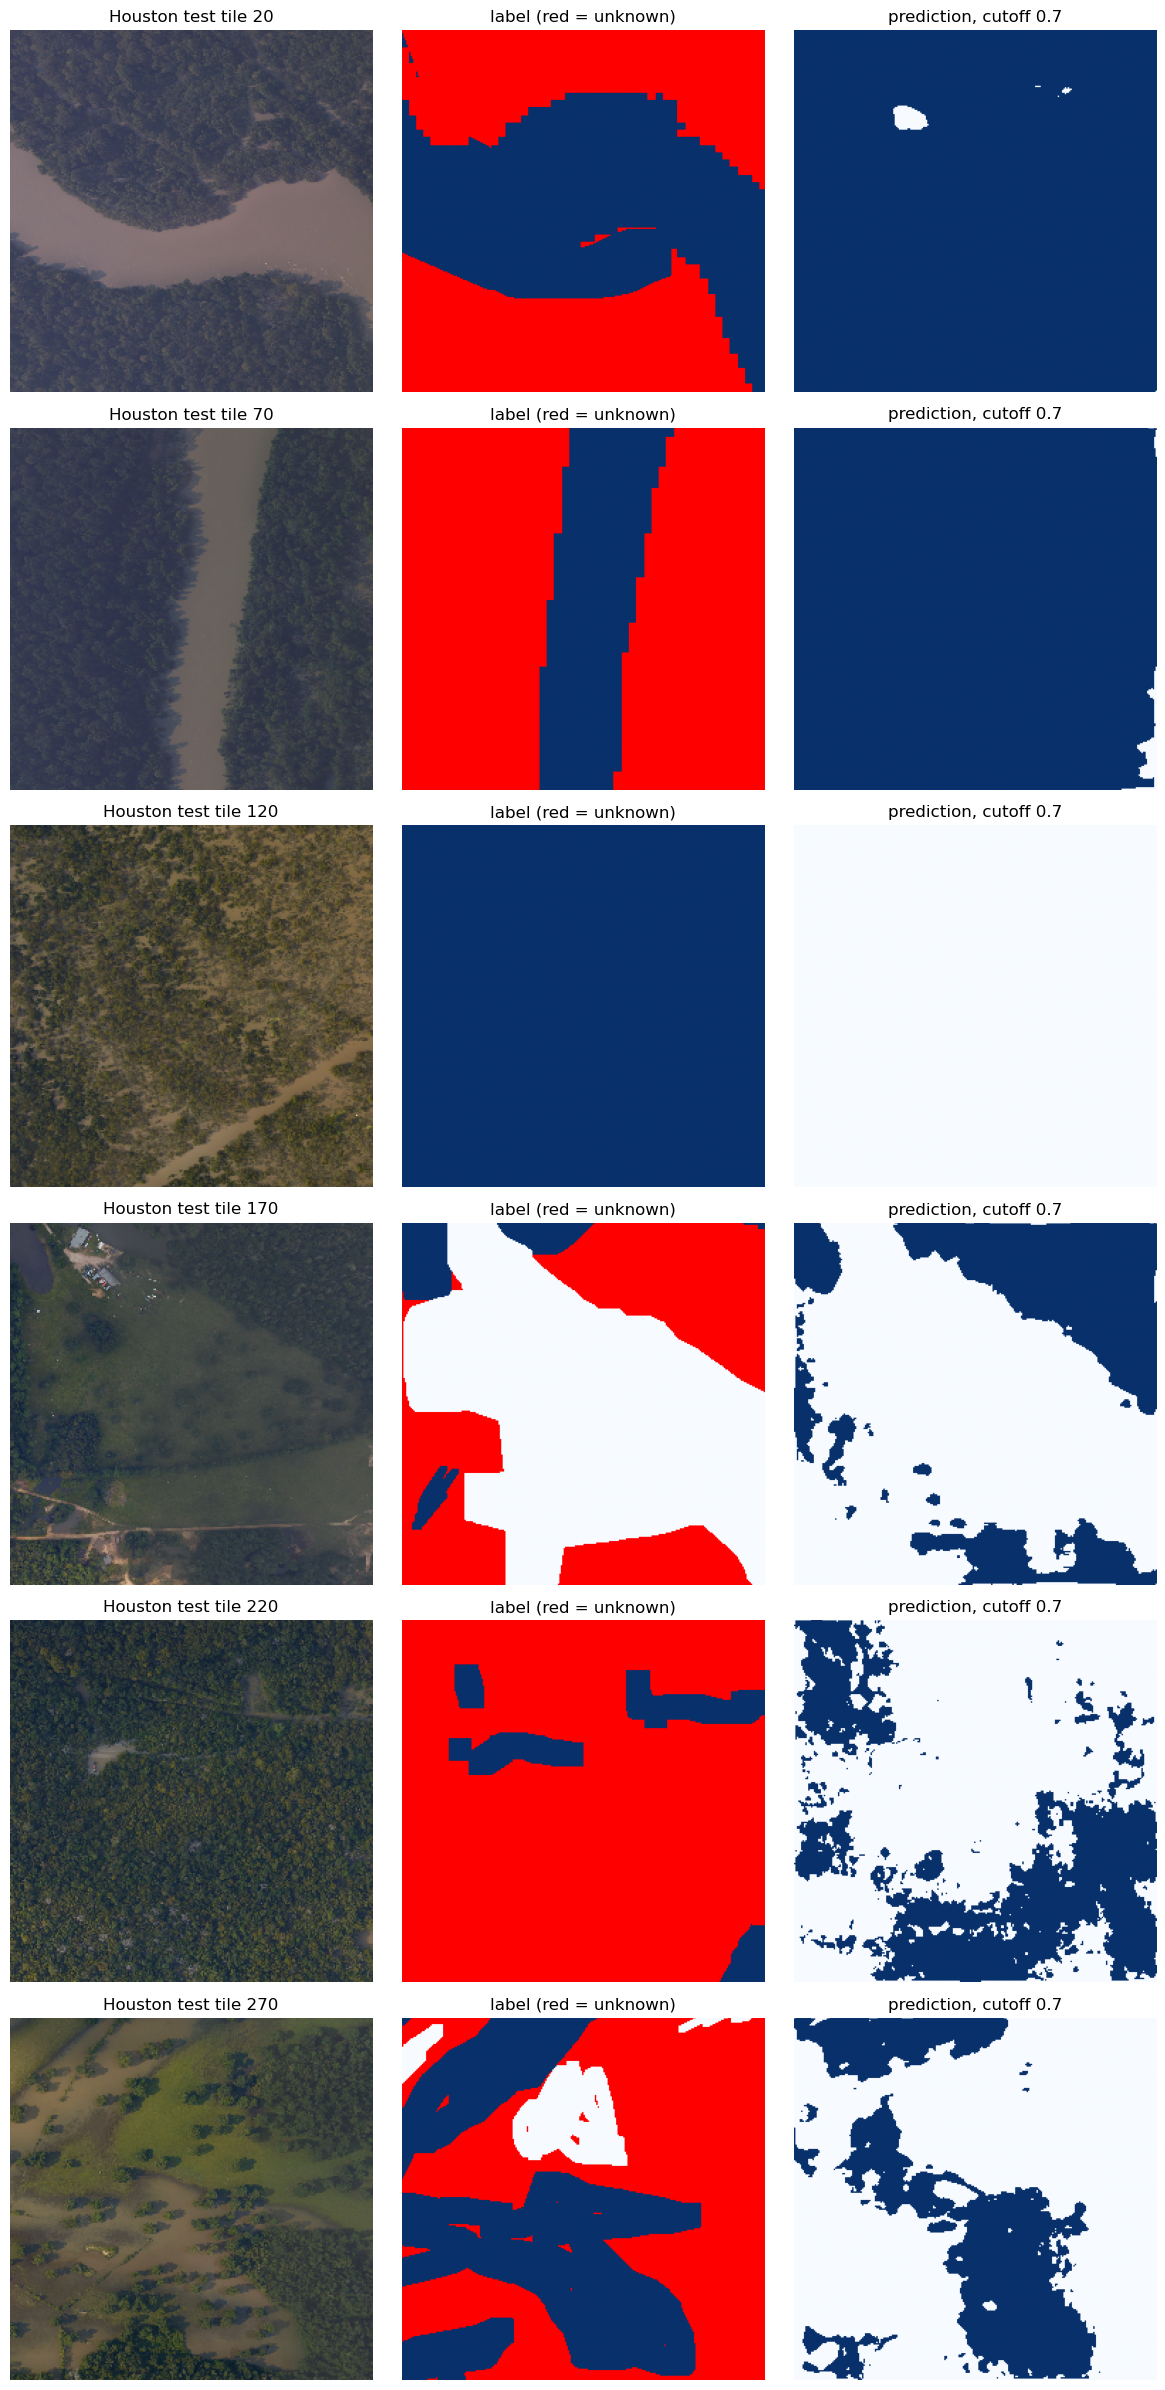

In [19]:
LABEL_CMAP = plt.get_cmap("Blues").copy()
LABEL_CMAP.set_bad("red")   # unknown (-1) pixels

tiles = [20, 70, 120, 170, 220, 270]
fig, axes = plt.subplots(len(tiles), 3, figsize=(12, 4 * len(tiles)))
for row, t in enumerate(tiles):
    axes[row, 0].imshow(X_test_rgb[t]);                       axes[row, 0].set_title(f"Houston test tile {t}")
    axes[row, 1].imshow(np.ma.masked_equal(y_test[t], -1), cmap=LABEL_CMAP, vmin=0, vmax=1); axes[row, 1].set_title("label (red = unknown)")
    axes[row, 2].imshow(test_probs[t] > CUTOFF, cmap="Blues", vmin=0, vmax=1); axes[row, 2].set_title(f"prediction, cutoff {CUTOFF}")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Things to keep in mind

- **FloodNet is a small addition.** One epoch's mosaics are only ~47 tiles next to ~1,970 Houston tiles. If the
  scores barely move, try `FLOODNET_WEIGHT = 3.0` or higher so the model sees each FloodNet tile more often.
- **FloodNet is mostly dry (~16% flood)** while Houston is mostly flooded, so it mainly adds dry examples. That could
  help with the baseline's mistakes on dry trees and dark roofs, but could also make the model call less flood on the
  heavily flooded Houston test images.
- **The val set is one image (12),** so the checkpoint and cutoff are tuned to one scene. Small differences in test
  IoU between the two models may be noise.
- **Only FloodNet's train split is used,** and only for training. All scores are on the Houston test images, so they
  can be compared directly with `unet_pretrained.ipynb` and `unet_dem.ipynb`.
- **Combining with the DEM model:** FloodNet would need a placeholder DEM channel (e.g. all zeros) to train
  `unet_dem.ipynb`'s 4-channel model. That's a possible next experiment.